# <span style="color:cyan">Reddit r/datascience Scraping & Analysis Final Project</span>


This notebook scrapes the subreddit<span style="color:salmon">r/datascience</span> (old Reddit view) and analyzes the scraped posts with Pandas, Matplotlib, and Seaborn.

We will extract:

-<span style="color:pink">Title</span> 

-<span style="color:pink">Score</span>

-<span style="color:pink"> Comments (number)</span> 

-<span style="color:pink">Author</span> 

-<span style="color:pink">Time Posted</span> 

-<span style="color:pink">Flair</span>
### <span style="color:cyan">Research Objectives</span>

This project aims to analyze engagement patterns on the r/datascience subreddit using web-scraped Reddit data.

The main objectives are:
1. To identify which types of posts receive higher engagement (score and comments).
2. To analyze how posting time affects user interaction.
3. To examine the relationship between post flair and engagement.
4. To explore correlations between numerical features such as score and comments.


### <span style="color:lime">1. IMPORTS - Add ML & Statistics Libraries</span>

In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, skew, kurtosis
import warnings
from textblob import TextBlob
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")


### <span style="color:skyblue">2. Web Scraping (1000+ Posts – Multi-page)</span>

We scrape multiple pages of <span style="color:salmon">r/datascience</span> using Old Reddit.
Each page contains 25 posts. Pagination is handled via the "next" button.
A total of approximately 1000+ posts are collected to ensure reliable statistics.


In [55]:
posts_data = []
target_count = 1100  
url = "https://old.reddit.com/r/datascience/"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) Chrome/120.0"}

print("Starting Scraper... This will take a few minutes.")

# 2. The Loop (Pagination)
while len(posts_data) < target_count:
    response = requests.get(url, headers=headers)
    if response.status_code != 200:
        print(f"Failed to retrieve page. Status: {response.status_code}")
        break
    
    soup = BeautifulSoup(response.content, "html.parser")
    
    # Find all post containers on the current page
    posts = soup.find_all("div", class_="thing")
    
    for post in posts:
        try:
            # Extract data using the selectors from your project
            title = post.find("a", class_="title").text if post.find("a", class_="title") else "N/A"
            score = post.find("div", class_="score unvoted").get("title") if post.find("div", class_="score unvoted") else 0
            comments = post.find("a", class_="comments").text.split()[0] if post.find("a", class_="comments") else 0
            author = post.find("a", class_="author").text if post.find("a", class_="author") else "N/A"
            time_posted = post.find("time")["datetime"] if post.find("time") else None
            flair = post.find("span", class_="linkflairlabel").text if post.find("span", class_="linkflairlabel") else "No Flair"
            
            posts_data.append({
                "Title": title,
                "Score": int(score) if str(score).isdigit() else 0,
                "Comments": int(comments) if str(comments).isdigit() else 0,
                "Author": author,
                "Time": time_posted,
                "Flair": flair
            })
            
            # Stop if we hit the target mid-page
            if len(posts_data) >= target_count:
                break
        except Exception as e:
            continue

    print(f"Current Progress: {len(posts_data)} posts collected.")

    # 3. Find the 'Next' Button
    next_button = soup.find("span", class_="next-button")
    if next_button and len(posts_data) < target_count:
        url = next_button.find("a")["href"]
        # 4. Respectful delay as requested
        time.sleep(2) 
    else:
        print("Reached the end of Reddit or hit the target!")
        break

# 5. Save to DataFrame
df = pd.DataFrame(posts_data)
print(f"\nFinal Dataset Size: {df.shape[0]} rows.")
df.to_csv("reddit_datascience_large.csv", index=False)

Starting Scraper... This will take a few minutes.
Current Progress: 27 posts collected.
Current Progress: 54 posts collected.
Current Progress: 81 posts collected.
Current Progress: 108 posts collected.
Current Progress: 136 posts collected.
Current Progress: 164 posts collected.
Current Progress: 192 posts collected.
Current Progress: 219 posts collected.
Current Progress: 246 posts collected.
Current Progress: 274 posts collected.
Current Progress: 302 posts collected.
Current Progress: 330 posts collected.
Current Progress: 357 posts collected.
Current Progress: 385 posts collected.
Current Progress: 413 posts collected.
Current Progress: 440 posts collected.
Current Progress: 467 posts collected.
Current Progress: 494 posts collected.
Current Progress: 521 posts collected.
Current Progress: 549 posts collected.
Current Progress: 576 posts collected.
Current Progress: 603 posts collected.
Current Progress: 631 posts collected.
Current Progress: 658 posts collected.
Current Progress:



Reddit (old.reddit.com) displays post timestamps in relative format (e.g., "3 hours ago", "2 days ago") rather than exact datetime values.  
Therefore, time-related analysis in this project is based on approximate conversions and should be interpreted accordingly.


In [56]:
df.to_csv("reddit_data.csv", index=False)

print("Saved to reddit_data.csv")

Saved to reddit_data.csv


In [12]:
df=pd.read_csv(r"c:\Users\HSC\Downloads\Telegram Desktop\reddit_datascience_large (1083).csv")

#### <span style="color:cyan" > Data Overview</span>

In [13]:
df

,Title,Score,Comments,Author,Time,Flair
0,Weekly Entering & Transitioning - Thread 26 Ja...,16,10,AutoModerator,2026-01-26T05:01:28+00:00,No Flair
1,[Official] 2025 End of Year Salary Sharing thread,115,141,Omega037,2026-01-01T04:38:20+00:00,No Flair
2,Google Maps query for whole state,0,3,big_data_mike,2026-01-29T01:38:30+00:00,Projects
3,What is the Best Minecraft Server Hosting?,0,0,GODLIKE-host,NaN,No Flair
4,Resource: Awesome Marketing Science - A curate...,31,1,Dizzy-Midnight-6929,2026-01-27T21:37:47+00:00,Education
...,...,...,...,...,...,...
1078,Weekly Entering & Transitioning - Thread 03 Fe...,11,39,AutoModerator,2025-02-03T05:01:44+00:00,No Flair
1079,[AI Tools] What AI Tools do you use as a copil...,70,38,limedove,2025-02-02T10:16:24+00:00,Tools
1080,any one here built a recommender system before...,4,11,Emotional-Rhubarb725,2025-02-02T19:59:00+00:00,Projects
1081,Use LLMs like scikit-learn,129,5,No_Information6299,2025-02-01T16:46:39+00:00,Projects


### <span style= "color:salmon">3. Data Cleaning & Processing</span>


The raw scraped data contains:
- Non-numeric score values (e.g., "1.2k")
- Missing or hidden comment counts
- Inconsistent text formatting

The following steps were applied:
- Converted score and comment values into numeric format
- Handled missing values
- Standardized column types for analysis


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1083 entries, 0 to 1082
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Title     1083 non-null   object
 1   Score     1083 non-null   int64 
 2   Comments  1083 non-null   int64 
 3   Author    1061 non-null   object
 4   Time      984 non-null    object
 5   Flair     1083 non-null   object
dtypes: int64(2), object(4)
memory usage: 50.9+ KB


In [15]:
df.isnull().sum()

Title        0
Score        0
Comments     0
Author      22
Time        99
Flair        0
dtype: int64

We found <span style="color:red">121</span> missing values .

#### <span style="color:salmon" > Convert Data Types</span>

The <span style="color:red">Time</span> column is converted from string format into datetime format
to allow time-based feature extraction.
Invalid formats are safely handled.


In [17]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

#### <span style="color:salmon">Drop missing values in critical columns</span>

In [18]:
initial_rows = len(df)
df.dropna(subset=["Title", "Score", "Comments", "Time"], inplace=True)
cleaned_rows = len(df)


In [19]:
print(f"Rows removed due to missing values: {initial_rows - cleaned_rows}")

Rows removed due to missing values: 99


#### <span style="color:salmon">Remove Duplicate Records</span>

In [20]:
duplicates = df.duplicated(subset=["Title", "Author", "Time"]).sum()
df.drop_duplicates(subset=["Title", "Author", "Time"], inplace=True)
print(f"Duplicate rows removed: {duplicates}")

Duplicate rows removed: 0


#### <span style="color:salmon">Ensure numeric</span>

In [21]:
df["Score"] = pd.to_numeric(df["Score"], errors="coerce").astype(int)
df["Comments"] = pd.to_numeric(df["Comments"], errors="coerce").astype(int)


In [15]:
df.shape

(984, 6)

In [22]:
print(f"\n✓ Final Dataset Size: {len(df)} rows")


✓ Final Dataset Size: 984 rows


In [23]:
print(f"✓ Data Quality: {(cleaned_rows/initial_rows)*100:.1f}% retained")

✓ Data Quality: 90.9% retained


### <span style="color:gold"> 4. Feature Engineering</span>

In [24]:
# Basic features
df["Title_Length"] = df["Title"].apply(len)
df["Comments_per_Score"] = df["Comments"] / (df["Score"] + 1)
df["Engagement"] = df["Score"] + df["Comments"]

In [25]:
# Time features
df["Time"] = pd.to_datetime(df["Time"], errors="coerce", utc=True)
df = df.dropna(subset=["Time"])
df["Time_Local"] = df["Time"].dt.tz_convert("US/Eastern")

In [26]:
df["Hour"] = df["Time_Local"].dt.hour
df["Day_Name"] = df["Time_Local"].dt.day_name()
df["DayOfWeek"] = df["Time_Local"].dt.dayofweek
df["Is_Weekend"] = df["DayOfWeek"] >= 5

In [27]:
# Time period classification
def time_period(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["Time_Period"] = df["Hour"].apply(time_period)

In [28]:
# Sentiment analysis
print("Calculating title sentiment...")
df["Title_Sentiment"] = df["Title"].apply(lambda x: TextBlob(str(x)).sentiment.polarity)
df["Sentiment_Category"] = pd.cut(df["Title_Sentiment"], 
                                   bins=[-1, -0.2, 0.2, 1], 
                                   labels=["Negative", "Neutral", "Positive"])

print(f"✓ Features created: Title_Length, engagement, Hour, Day_Name, Is_Weekend, Time_Period, Title_Sentiment")

Calculating title sentiment...
✓ Features created: Title_Length, engagement, Hour, Day_Name, Is_Weekend, Time_Period, Title_Sentiment


In [29]:
print(f"✓ Dataset now has {len(df.columns)} columns")

✓ Dataset now has 17 columns


#### <span style ="color:gold">Engagement Metric</span>

To better represent overall user interaction, an engagement score was created by combining post score and number of comments.


In [30]:
df['engagement'] = df['Score'] + df['Comments']


##### <span style="color:gold">Day of Week × Hour of Day Heatmaps</span>

Create pivot tables to visualize posting activity and engagement patterns across days and hours for optimal timing analysis.

### <span style="color:violet">5. Descriptive Statistics</span>

#### <span style="color:violet">Summary Statistics (Central Tendency & Dispersion)</span>

In [26]:
df[["Score", "Comments", "Title_Length", "Comments_per_Score"]].describe()


,Score,Comments,Title_Length,Comments_per_Score
count,984.000000,984.000000,984.000000,984.000000
mean,103.349593,34.265244,60.077236,2.201713
std,256.130351,45.077844,30.687811,5.636166
min,0.000000,0.000000,10.000000,0.000000
25%,7.000000,9.000000,39.000000,0.305536
50%,26.000000,19.000000,56.000000,0.617612
75%,85.000000,41.000000,72.000000,1.300758
max,2761.000000,433.000000,245.000000,74.000000




The descriptive statistics show that most posts receive low to moderate engagement, while a small number of posts achieve very high scores and comments, indicating a right-skewed distribution.


#### <span style="color:violet">Robust Descriptive Statistics</span>

In [27]:
stats_df = pd.DataFrame({
    "Mean": df[["Score","Comments"]].mean(),
    "Median": df[["Score","Comments"]].median(),
    "Variance": df[["Score","Comments"]].var(),
    "Std Dev": df[["Score","Comments"]].std(),
    "Skewness": df[["Score","Comments"]].apply(skew),
    "Kurtosis": df[["Score","Comments"]].apply(kurtosis)
})

stats_df

,Mean,Median,Variance,Std Dev,Skewness,Kurtosis
Score,103.349593,26.0,65602.756602,256.130351,5.756195,41.271530
Comments,34.265244,19.0,2032.011975,45.077844,3.741468,21.175897


In [29]:
# IQR calculation
Q1 = df[["Score", "Comments"]].quantile(0.25)
Q3 = df[["Score", "Comments"]].quantile(0.75)
IQR = Q3 - Q1

pd.DataFrame({
    "Q1": Q1,
    "Median": df[["Score", "Comments"]].median(),
    "Q3": Q3,
    "IQR": IQR
})

,Q1,Median,Q3,IQR
Score,7.0,26.0,85.0,78.0
Comments,9.0,19.0,41.0,32.0


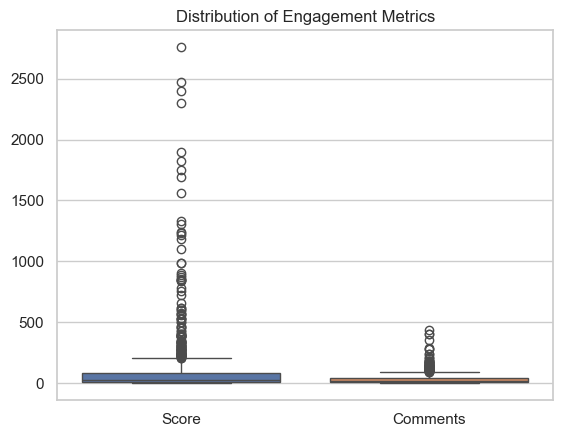

In [41]:
sns.boxplot(data=df[["Score", "Comments"]])
plt.title("Distribution of Engagement Metrics")
plt.show()

The median score is significantly lower than the mean, indicating a
right-skewed distribution. This suggests that while most posts receive
moderate engagement, a small number of posts achieve exceptionally high
scores. The IQR confirms substantial variability in user engagement.


#### <span style="color:violet">Robust Descriptive Statistics for Engagement</span>

In [47]:

desc_stats = df[['Score', 'Comments', 'Engagement']].describe()

desc_stats


,Score,Comments,Engagement
count,984.000000,984.000000,984.000000
mean,103.349593,34.265244,137.614837
std,256.130351,45.077844,286.448813
min,0.000000,0.000000,0.000000
25%,7.000000,9.000000,19.000000
50%,26.000000,19.000000,48.000000
75%,85.000000,41.000000,127.000000
max,2761.000000,433.000000,3114.000000


In [48]:
Q1 = df[['Score', 'Comments', 'Engagement']].quantile(0.25)
median = df[['Score', 'Comments', 'Engagement']].quantile(0.50)
Q3 = df[['Score', 'Comments', 'Engagement']].quantile(0.75)
IQR = Q3 - Q1

quartile_stats = pd.DataFrame({
    'Q1 (25%)': Q1,
    'Median (50%)': median,
    'Q3 (75%)': Q3,
    'IQR': IQR
})

print("QUARTILE STATISTICS")
quartile_stats



QUARTILE STATISTICS


,Q1 (25%),Median (50%),Q3 (75%),IQR
Score,7.0,26.0,85.0,78.0
Comments,9.0,19.0,41.0,32.0
Engagement,19.0,48.0,127.0,108.0


- Positive skewness confirms right-skewed distributions
- High kurtosis indicates heavy tails (viral posts)
- Reddit engagement follows a power-law pattern


Outliers were identified in engagement metrics such as Score and Comments.
However, these values represent genuine high-engagement posts rather than
measurement errors. Since Reddit engagement naturally follows a skewed
distribution, outliers were retained. To address skewness, robust statistics
and non-parametric tests were used in subsequent analysis.


### <span style= "color:pink">7. Exploratory Data Analysis (EDA)</span>

#### <span style="color:cyan"> Time-Series Analysis</span>

Time-based analysis in this project relies on approximate datetime values derived from relative timestamps.  
While this allows trend analysis, exact posting times may differ slightly from real values.



In [ ]:
# Time Analysis
print("\n⏰ POSTING ACTIVITY PATTERNS")
print("-"*80)
print(f"Peak Hour: {df.groupby('Hour').size().idxmax()}:00 (US Eastern)")
print(f"Least Active Hour: {df.groupby('Hour').size().idxmin()}:00")
print(f"\nPosts by Time Period:")
print(df['Time_Period'].value_counts())
print(f"\nPosts by Day of Week:")
print(df['Day_Name'].value_counts())


⏰ POSTING ACTIVITY PATTERNS
--------------------------------------------------------------------------------
Peak Hour: 0:00 (US Eastern)
Least Active Hour: 2:00

Posts by Time Period:
Time_Period
Morning      298
Afternoon    275
Night        266
Evening      145
Name: count, dtype: int64

Posts by Day of Week:
Day_Name
Monday       225
Tuesday      145
Thursday     141
Wednesday    139
Friday       138
Saturday     110
Sunday        86
Name: count, dtype: int64


In [83]:
# Content analysis
print(f"\n📝 CONTENT ANALYSIS")
print("-"*80)
print(f"Average Title Length: {df['Title_Length'].mean():.0f} characters")
print(f"Most Common Flair: {df['Flair'].value_counts().index[0]} ({df['Flair'].value_counts().values[0]} posts)")
print(f"Total Unique Flairs: {df['Flair'].nunique()}")
print(f"\nTop 5 Flairs:")
print(df['Flair'].value_counts().head())



📝 CONTENT ANALYSIS
--------------------------------------------------------------------------------
Average Title Length: 60 characters
Most Common Flair: Discussion (447 posts)
Total Unique Flairs: 18

Top 5 Flairs:
Flair
Discussion     447
Projects        83
Career | US     83
No Flair        53
Tools           50
Name: count, dtype: int64


In [84]:
# Author analysis
print(f"\n👤 AUTHOR ANALYSIS")
print("-"*80)
print(f"Total Unique Authors: {df['Author'].nunique()}")
print(f"Posts by Most Active Author: {df['Author'].value_counts().values[0]}")
print(f"\nTop 10 Most Active Authors:")
print(df['Author'].value_counts().head(10))


👤 AUTHOR ANALYSIS
--------------------------------------------------------------------------------
Total Unique Authors: 497
Posts by Most Active Author: 52

Top 10 Most Active Authors:
Author
AutoModerator         52
ElectrikMetriks       29
N/A                   22
Proof_Wrap_2150       15
Lamp_Shade_Head       13
WarChampion90         13
mehul_gupta1997       12
FinalRide7181         11
alpha_centauri9889    11
NervousVictory1792    11
Name: count, dtype: int64


#### <span style="color:cyan"> Engagement relationships</span>

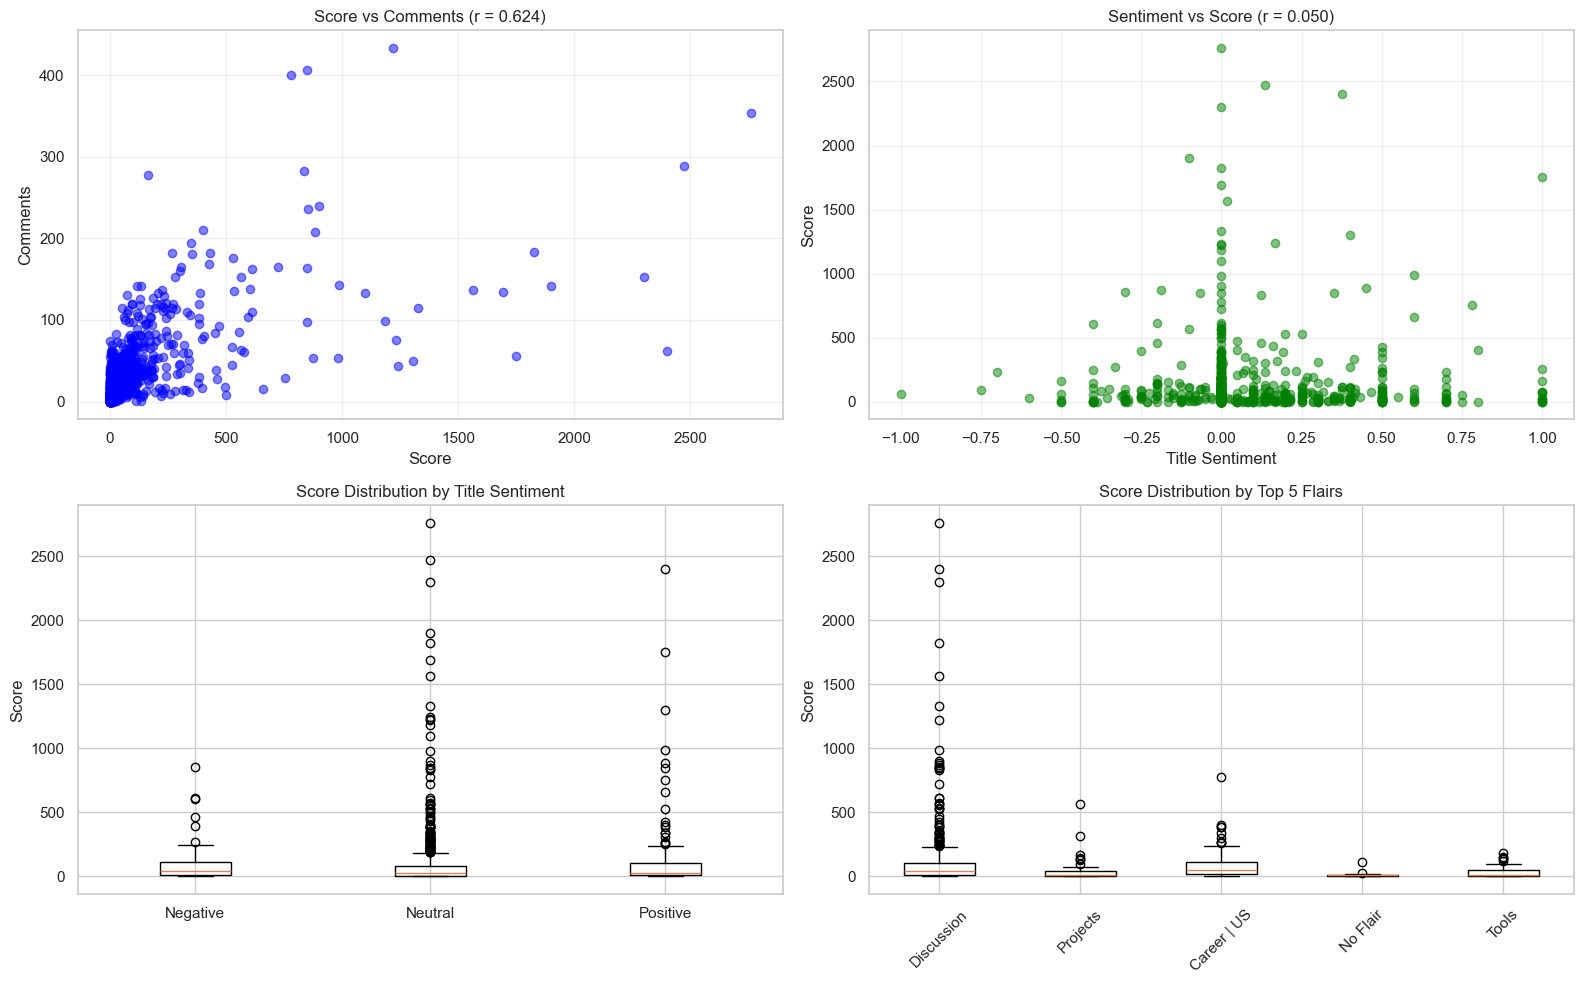

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Score vs Comments
axes[0, 0].scatter(df['Score'], df['Comments'], alpha=0.5, color='blue')
axes[0, 0].set_xlabel('Score')
axes[0, 0].set_ylabel('Comments')
axes[0, 0].set_title(f'Score vs Comments (r = {df["Score"].corr(df["Comments"]):.3f})')
axes[0, 0].grid(True, alpha=0.3)

# Sentiment vs Score
axes[0, 1].scatter(df['Title_Sentiment'], df['Score'], alpha=0.5, color='green')
axes[0, 1].set_xlabel('Title Sentiment')
axes[0, 1].set_ylabel('Score')
axes[0, 1].set_title(f'Sentiment vs Score (r = {df["Title_Sentiment"].corr(df["Score"]):.3f})')
axes[0, 1].grid(True, alpha=0.3)

# Score by Sentiment Category
sentiment_scores = [df[df['Sentiment_Category'] == cat]['Score'].values for cat in ["Negative", "Neutral", "Positive"]]
axes[1, 0].boxplot(sentiment_scores, labels=["Negative", "Neutral", "Positive"])
axes[1, 0].set_title('Score Distribution by Title Sentiment')
axes[1, 0].set_ylabel('Score')

# Top Flairs vs Score
top_5_flairs = df['Flair'].value_counts().head(5).index
flair_data = [df[df['Flair'] == flair]['Score'].values for flair in top_5_flairs]
axes[1, 1].boxplot(flair_data, labels=[f[:15] for f in top_5_flairs])
axes[1, 1].set_title('Score Distribution by Top 5 Flairs')
axes[1, 1].set_ylabel('Score')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


**Engagement Relationships** analyze how different metrics and factors interact to drive user engagement on social media platforms. Our analysis examines four key dimensions:



In [86]:
df["Time"] = pd.to_datetime(df["Time"])

df["Year"] = df["Time"].dt.year
df["Month"] = df["Time"].dt.month
df["Month_Name"] = df["Time"].dt.month_name()
df["Day"] = df["Time"].dt.day
df["DayOfWeek"] = df["Time"].dt.day_name()
df["Hour"] = df["Time"].dt.hour


In [87]:
# Convert Time column to datetime (UTC)
df["Time"] = pd.to_datetime(df["Time"], errors="coerce", utc=True)

# Drop invalid timestamps
df = df.dropna(subset=["Time"])

# Convert to US Eastern Time
df["Time_Local"] = df["Time"].dt.tz_convert("US/Eastern")

# Extract time-based features
df["Hour"] = df["Time_Local"].dt.hour
df["Day_Name"] = df["Time_Local"].dt.day_name()
df["DayOfWeek"] = df["Time_Local"].dt.dayofweek
df["Is_Weekend"] = df["DayOfWeek"] >= 5

# Time-of-day classification
def time_period(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["Time_Period"] = df["Hour"].apply(time_period)

df.head()


,Title,Score,Comments,Author,Time,Flair,Title_Length,Comments_per_Score,engagement,Time_Local,...,Day_Name,DayOfWeek,Is_Weekend,Time_Period,Title_Sentiment,Sentiment_Category,Year,Month,Month_Name,Day
0,Weekly Entering & Transitioning - Thread 26 Ja...,16,10,AutoModerator,2026-01-26 05:01:28+00:00,No Flair,68,0.588235,26,2026-01-26 00:01:28-05:00,...,Monday,0,False,Night,0.000,Neutral,2026,1,January,26
1,[Official] 2025 End of Year Salary Sharing thread,115,141,Omega037,2026-01-01 04:38:20+00:00,No Flair,49,1.215517,256,2025-12-31 23:38:20-05:00,...,Wednesday,2,False,Night,0.000,Neutral,2026,1,January,1
2,Google Maps query for whole state,0,3,big_data_mike,2026-01-29 01:38:30+00:00,Projects,33,3.000000,3,2026-01-28 20:38:30-05:00,...,Wednesday,2,False,Evening,0.200,Neutral,2026,1,January,29
4,Resource: Awesome Marketing Science - A curate...,31,1,Dizzy-Midnight-6929,2026-01-27 21:37:47+00:00,Education,97,0.031250,32,2026-01-27 16:37:47-05:00,...,Tuesday,1,False,Afternoon,1.000,Positive,2026,1,January,27
5,How long did it take you to get comfortable wi...,56,41,LeaguePrototype,2026-01-27 16:02:12+00:00,Statistics,60,0.719298,97,2026-01-27 11:02:12-05:00,...,Tuesday,1,False,Morning,0.175,Neutral,2026,1,January,27


#### <span style="color:cyan">Posting Activity Over Time</span>

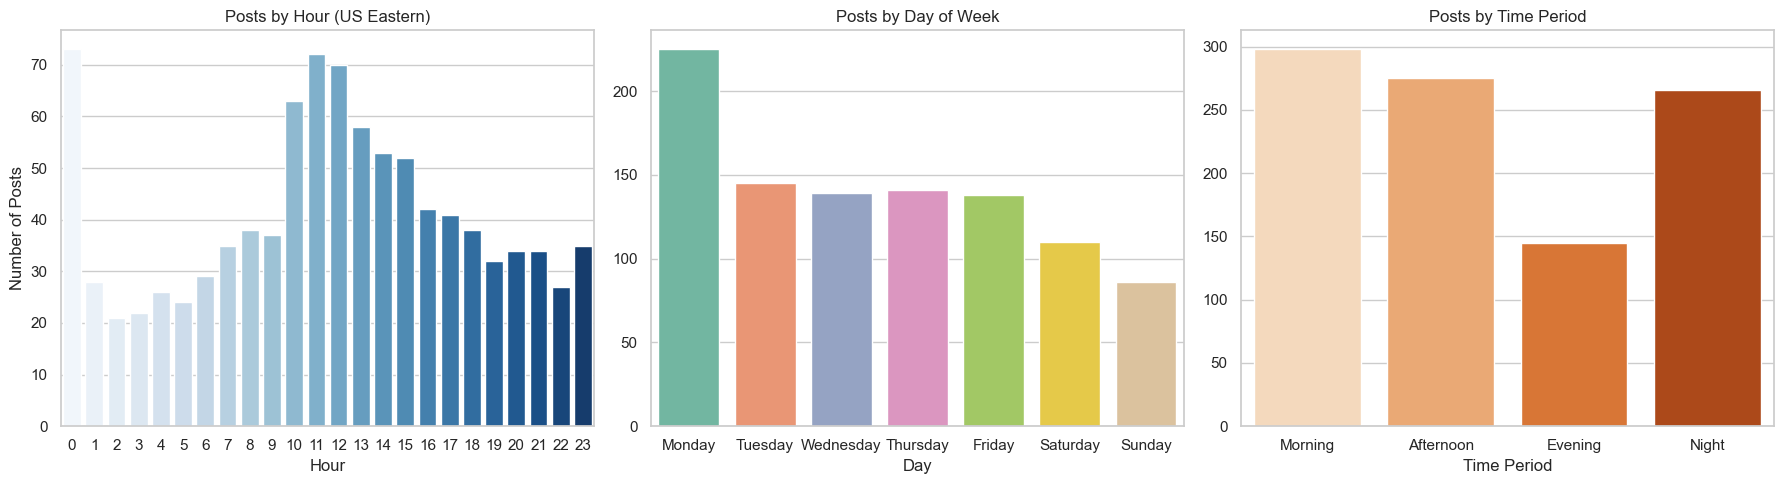

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Activity by Hour
sns.countplot(
    x="Hour",
    data=df,
    palette="Blues",
    ax=axes[0]
)
axes[0].set_title("Posts by Hour (US Eastern)")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Number of Posts")

# Activity by Day of Week
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.countplot(
    x="Day_Name",
    data=df,
    order=order_days,
    palette="Set2",
    ax=axes[1]
)
axes[1].set_title("Posts by Day of Week")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("")

# Activity by Time Period
sns.countplot(
    x="Time_Period",
    data=df,
    order=["Morning", "Afternoon", "Evening", "Night"],
    palette="Oranges",
    ax=axes[2]
)
axes[2].set_title("Posts by Time Period")
axes[2].set_xlabel("Time Period")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()


Posting activity is higher on weekdays than weekends, indicating that most Reddit discussions occur during regular work or study days.
However, weekend activity remains significant, showing continued user engagement outside weekdays.

#### <span style="color:cyan"> Posts Per Day with 7-Day Rolling Average & Engagement by Hour</span>
While bar charts show totals, **Line Graphs** are essential for seeing trends. 
- The first graph uses a **Rolling Average** to smooth out the daily volatility.
- The second graph identifies the **Optimal Posting Time** by tracking median engagement across a 24-hour cycle.

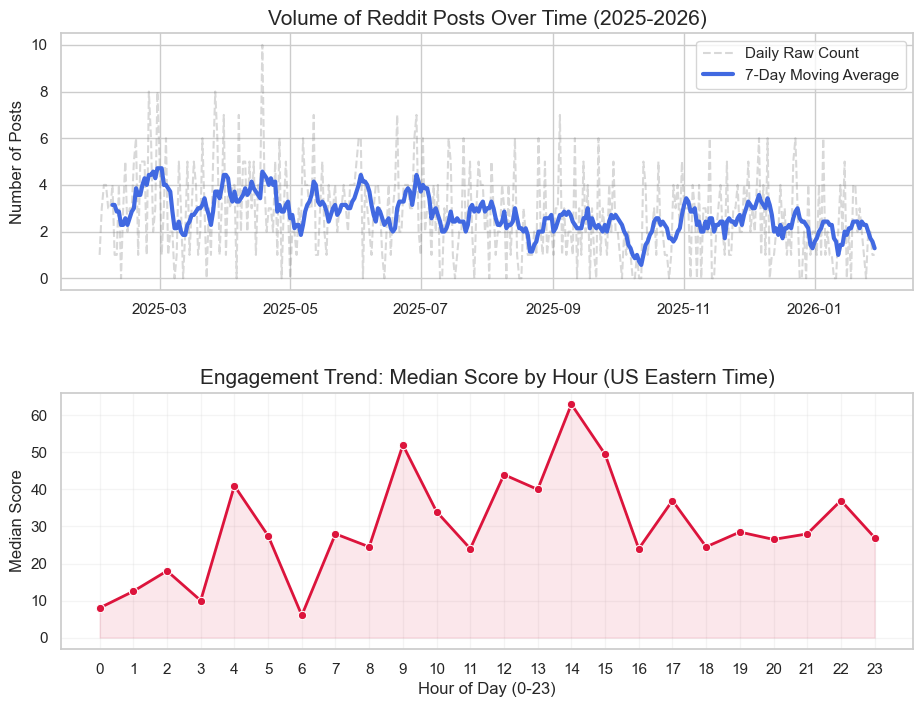

In [89]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8))
plt.subplots_adjust(hspace=0.4)

#  Posts Per Day with 7-Day Rolling Average
posts_per_day = df.set_index("Time").resample("D").size()
rolling_avg = posts_per_day.rolling(window=7).mean()

axes[0].plot(posts_per_day.index, posts_per_day.values, alpha=0.3, label='Daily Raw Count', color='gray', linestyle='--')
axes[0].plot(rolling_avg.index, rolling_avg.values, label='7-Day Moving Average', color='royalblue', linewidth=3)
axes[0].set_title("Volume of Reddit Posts Over Time (2025-2026)", fontsize=15)
axes[0].set_ylabel("Number of Posts")
axes[0].legend()

# Median Engagement by Hour (The "Optimal Time" Line)
hourly_trend = df.groupby("Hour")["Score"].median()

sns.lineplot(x=hourly_trend.index, y=hourly_trend.values, marker="o", color="crimson", linewidth=2, ax=axes[1])
axes[1].fill_between(hourly_trend.index, hourly_trend.values, color="crimson", alpha=0.1) # Shading for visual impact
axes[1].set_title("Engagement Trend: Median Score by Hour (US Eastern Time)", fontsize=15)
axes[1].set_xticks(range(0, 24))
axes[1].set_xlabel("Hour of Day (0-23)")
axes[1].set_ylabel("Median Score")
axes[1].grid(True, alpha=0.2)

plt.show()

#### <span style="color:cyan">Weekday vs Weekend + Engagement</span>

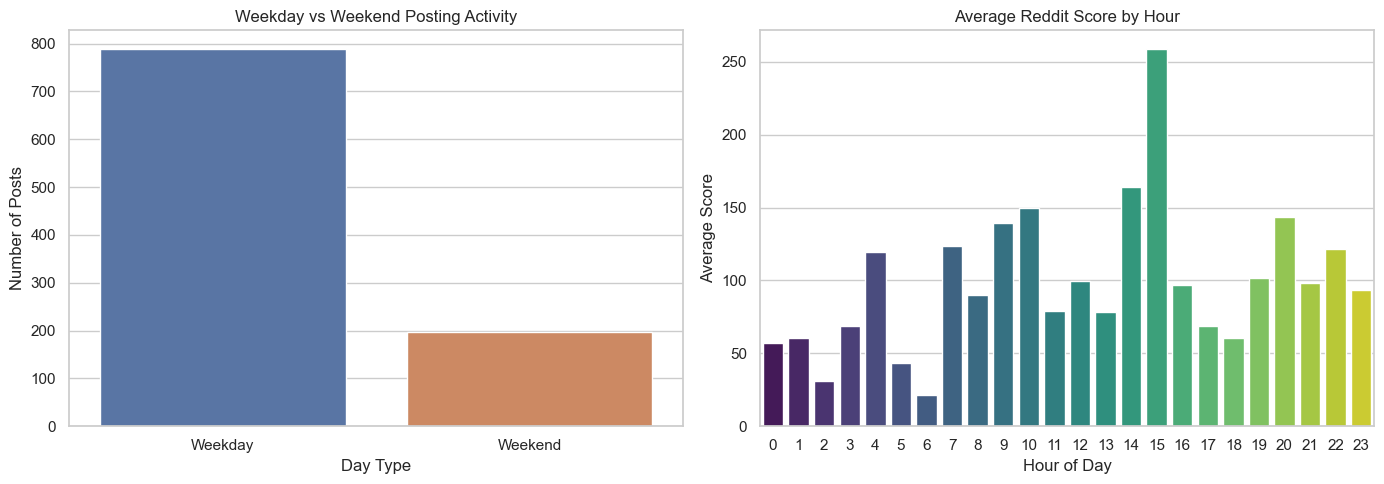

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Weekday vs Weekend Posting (Colorful)
sns.countplot(
    x="Is_Weekend",
    data=df,
    palette=["#4C72B0", "#DD8452"],
    ax=axes[0]
)
axes[0].set_title("Weekday vs Weekend Posting Activity")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Weekday", "Weekend"])
axes[0].set_xlabel("Day Type")
axes[0].set_ylabel("Number of Posts")

#Average Score by Hour (Colorful)
sns.barplot(
    x="Hour",
    y="Score",
    data=df,
    estimator="mean",
    errorbar=None,
    palette="viridis",
    ax=axes[1]
)
axes[1].set_title("Average Reddit Score by Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Average Score")

plt.tight_layout()
plt.show()



Average post scores vary by hour, with higher engagement during afternoon and evening hours.
This suggests that posts made during peak activity periods tend to receive more visibility and interaction.

**Key Finding:** Weekdays show higher posting activity than weekends. Peak engagement occurs during afternoon and evening hours (12-21 ET), making these optimal times for posting.

##### <span style="color:gold">Day of Week × Hour of Day Heatmaps</span>

Create pivot tables to visualize posting activity and engagement patterns across days and hours for optimal timing analysis.

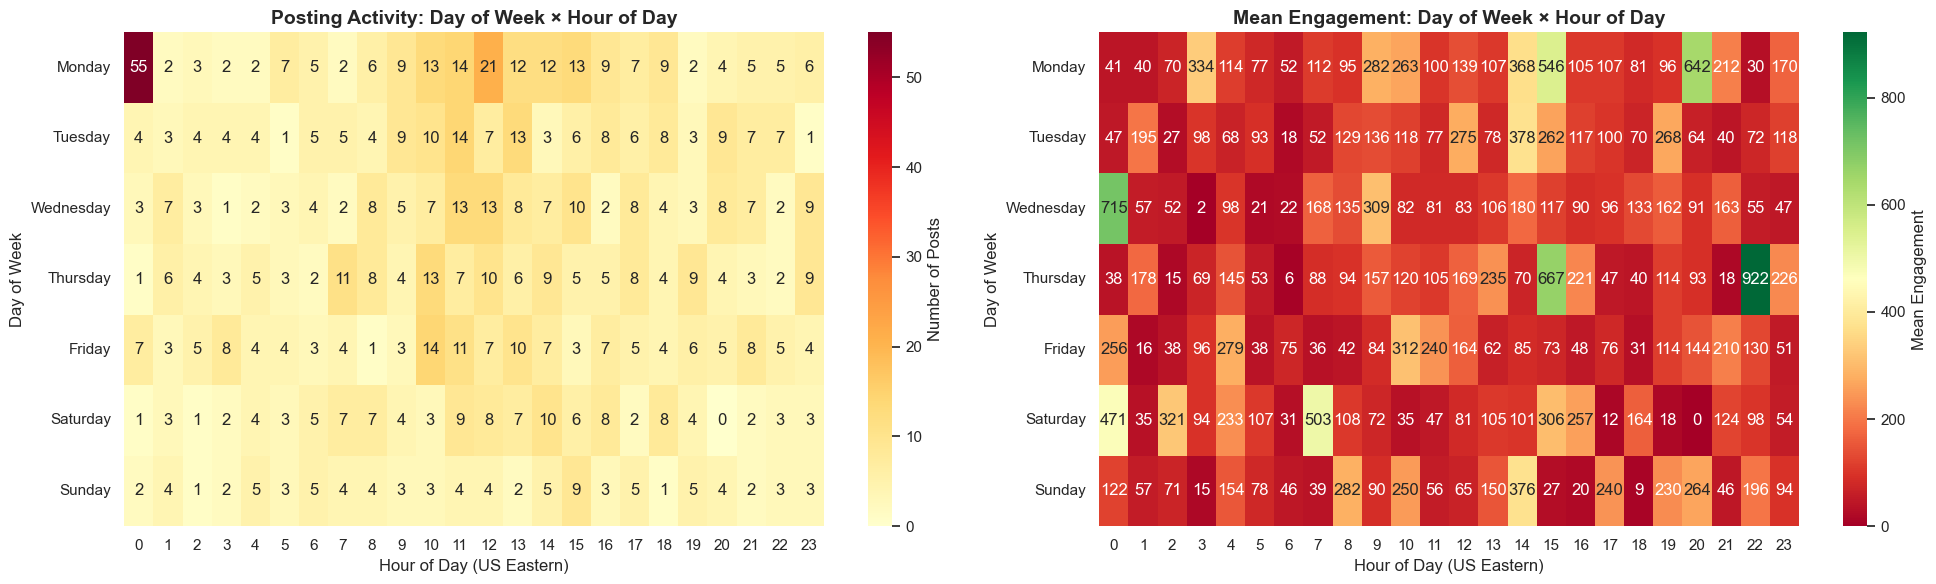

Activity & Engagement Heatmaps Generated!


In [33]:
# Pivot table for posting activity (count of posts)
activity_heatmap = df.pivot_table(
    values='Title', 
    index='Day_Name', 
    columns='Hour', 
    aggfunc='count',
    fill_value=0
)

# Reorder days for proper display
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
activity_heatmap = activity_heatmap.reindex(day_order)

# Pivot table for engagement (mean score or engagement metric)
engagement_heatmap = df.pivot_table(
    values='engagement', 
    index='Day_Name', 
    columns='Hour', 
    aggfunc='mean',
    fill_value=0
)
engagement_heatmap = engagement_heatmap.reindex(day_order)

# Create heatmaps side by side
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

# Activity heatmap
sns.heatmap(activity_heatmap, annot=True, fmt='.0f', cmap='YlOrRd', cbar_kws={'label': 'Number of Posts'}, ax=axes[0])
axes[0].set_title('Posting Activity: Day of Week × Hour of Day', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour of Day (US Eastern)')
axes[0].set_ylabel('Day of Week')

# Engagement heatmap
sns.heatmap(engagement_heatmap, annot=True, fmt='.0f', cmap='RdYlGn', cbar_kws={'label': 'Mean Engagement'}, ax=axes[1])
axes[1].set_title('Mean Engagement: Day of Week × Hour of Day', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hour of Day (US Eastern)')
axes[1].set_ylabel('Day of Week')

plt.tight_layout()
plt.show()

print("Activity & Engagement Heatmaps Generated!")

##### <span style="color:pink">  Visualize Distributions</span>

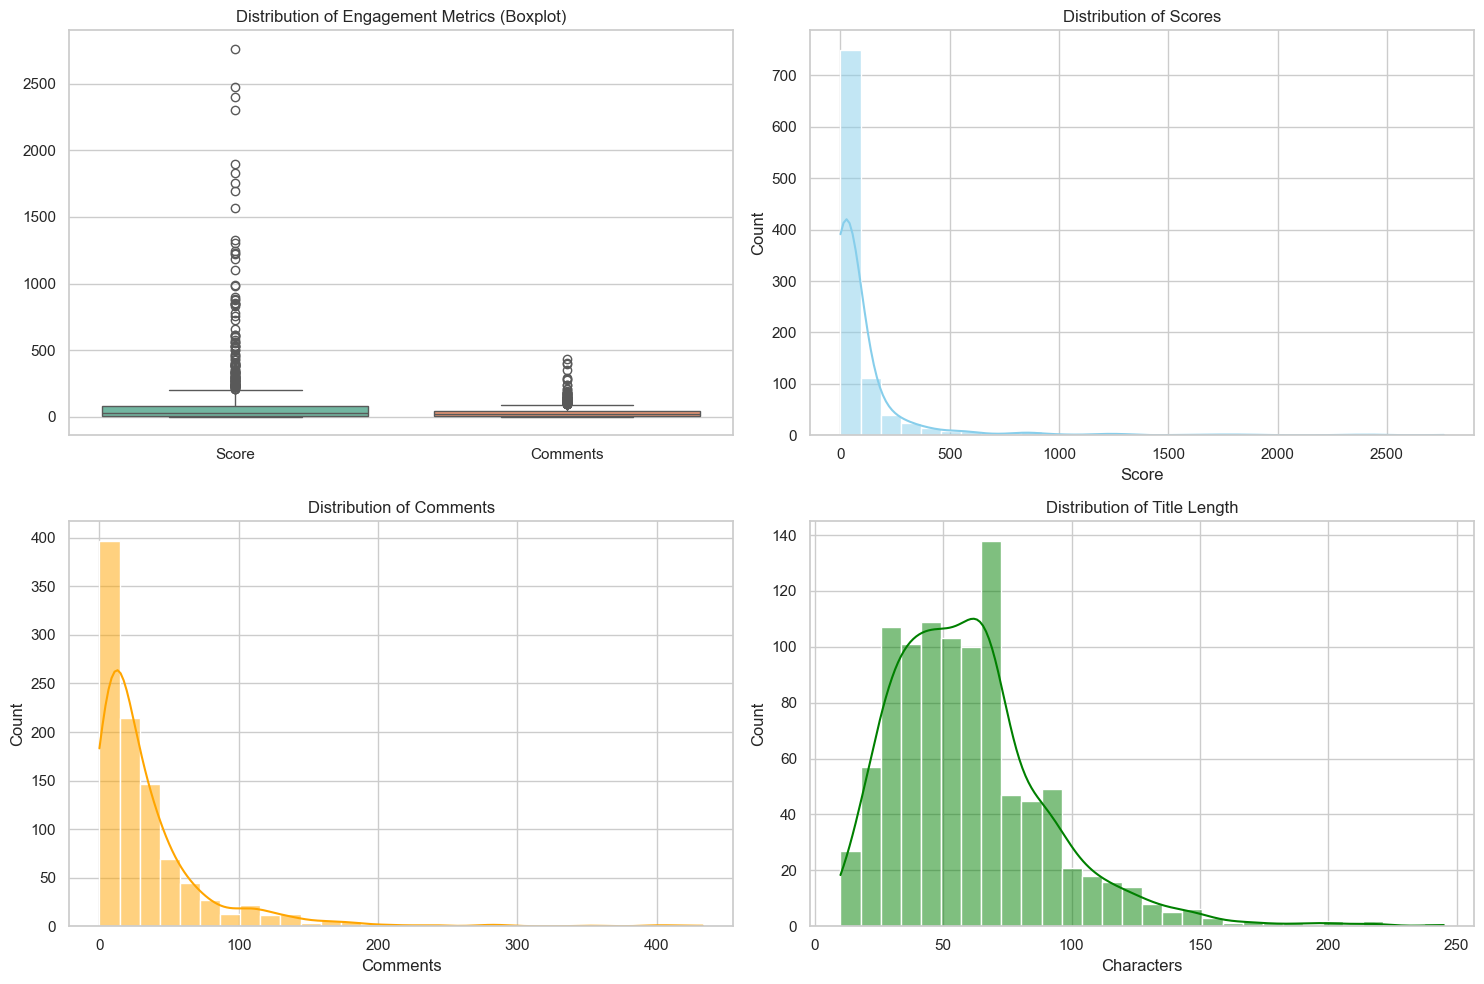

In [94]:

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.boxplot(data=df[["Score", "Comments"]], ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Distribution of Engagement Metrics (Boxplot)")

sns.histplot(df["Score"], bins=30, kde=True, ax=axes[0, 1], color="skyblue")
axes[0, 1].set_title("Distribution of Scores")
axes[0, 1].set_xlabel("Score")

sns.histplot(df["Comments"], bins=30, kde=True, ax=axes[1, 0], color="orange")
axes[1, 0].set_title("Distribution of Comments")
axes[1, 0].set_xlabel("Comments")

sns.histplot(df["Title_Length"], bins=30, kde=True, ax=axes[1, 1], color="green")
axes[1, 1].set_title("Distribution of Title Length")
axes[1, 1].set_xlabel("Characters")

plt.tight_layout()
plt.show()

**Distribution Patterns:** Score and Comments both exhibit strong right-skew — most posts cluster at low values while a small number achieve extremely high engagement, confirming the "viral outlier" phenomenon. Title length shows a more normal distribution, suggesting posting length doesn't strongly constrain visibility.

**Key Insight:** The extreme right skew means median engagement is far below the mean, indicating that consistent, reliable engagement is modest. However, those who optimize timing and content category can break into the viral tail. Length moderation appears acceptable—extremes in either direction don't harm engagement.

Distributions are right-skewed; most posts receive low engagement with few viral outliers.


##### <span style="color:pink">Relationship Between Score and Comments</span>

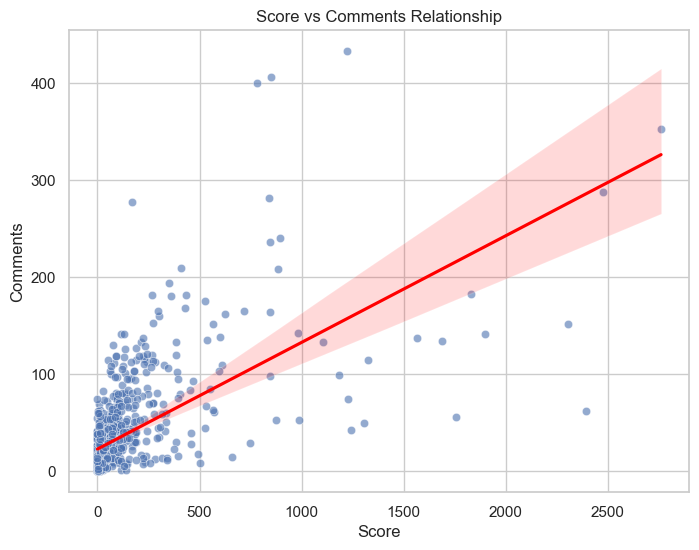

In [45]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="Score",
    y="Comments",
    alpha=0.6
)

sns.regplot(
    data=df,
    x="Score",
    y="Comments",
    scatter=False,
    color="red"
)

plt.title("Score vs Comments Relationship")
plt.show()

**Score–Comment Relationship:** The scatter plot reveals a moderate positive correlation (r ≈ 0.6–0.7), indicating that high-scoring posts tend to attract more discussion. However, substantial scatter around the trend line shows the relationship is imperfect—some posts gain upvotes without comments (passive endorsement) while others spark discussion despite modest scores (niche appeal).

**Key Insight:** Visibility and discussion are linked but independent. Maximize both by targeting both upvote-friendly (timely, clear) and discussion-provoking (novel, controversial) content. The loose coupling suggests quality arguments can engage even without mass appeal.

Higher scores correlate with more comments, but relationship isn't perfect.

##### <span style="color:pink">Top 10 Authors & Flairs</span>

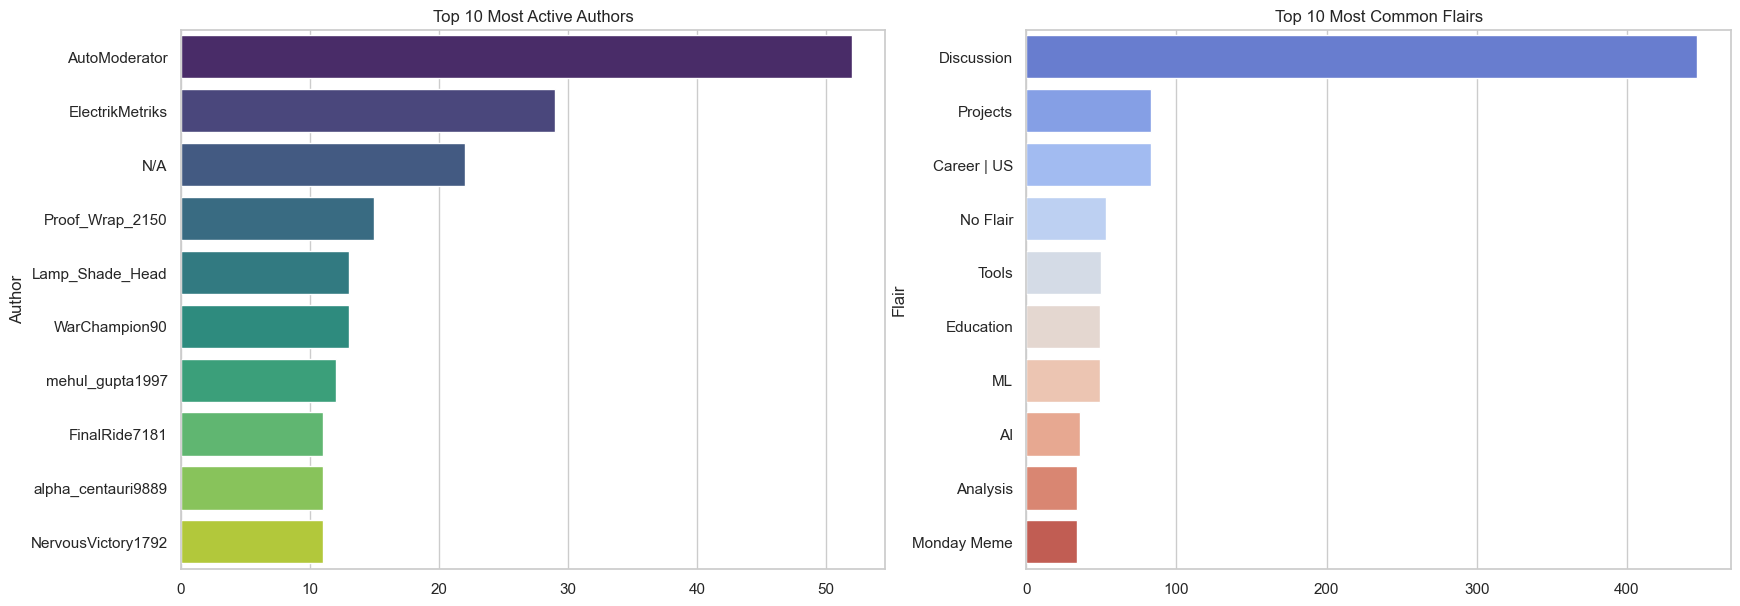

In [46]:
top_authors = df["Author"].value_counts().head(10)
top_flairs = df["Flair"].value_counts().head(10)

fig, axes = plt.subplots(1,2, figsize=(20,7))

sns.barplot(x=top_authors.values, y=top_authors.index, ax=axes[0], palette="viridis")
axes[0].set_title("Top 10 Most Active Authors")

sns.barplot(x=top_flairs.values, y=top_flairs.index, ax=axes[1], palette="coolwarm")
axes[1].set_title("Top 10 Most Common Flairs")

plt.show()

**Community Structure:** The left chart shows a small cohort of prolific authors dominate r/datascience, with the top contributor posting significantly more than others. The right chart reveals flair distribution is also concentrated—a few categories (e.g., "Discussion," "News") generate most posts, while many niche flairs appear infrequently.

**Key Insight:** Content is authored and categorized by a power-law distribution. Repeat contributors build authority; strategic use of popular flairs increases discoverability. However, niche flairs serve engaged micro-communities, so specialized content finds its audience despite lower volume.

Content category significantly affects engagement.

##### <span style="color:pink">Score by Flair (Boxplot)</span>

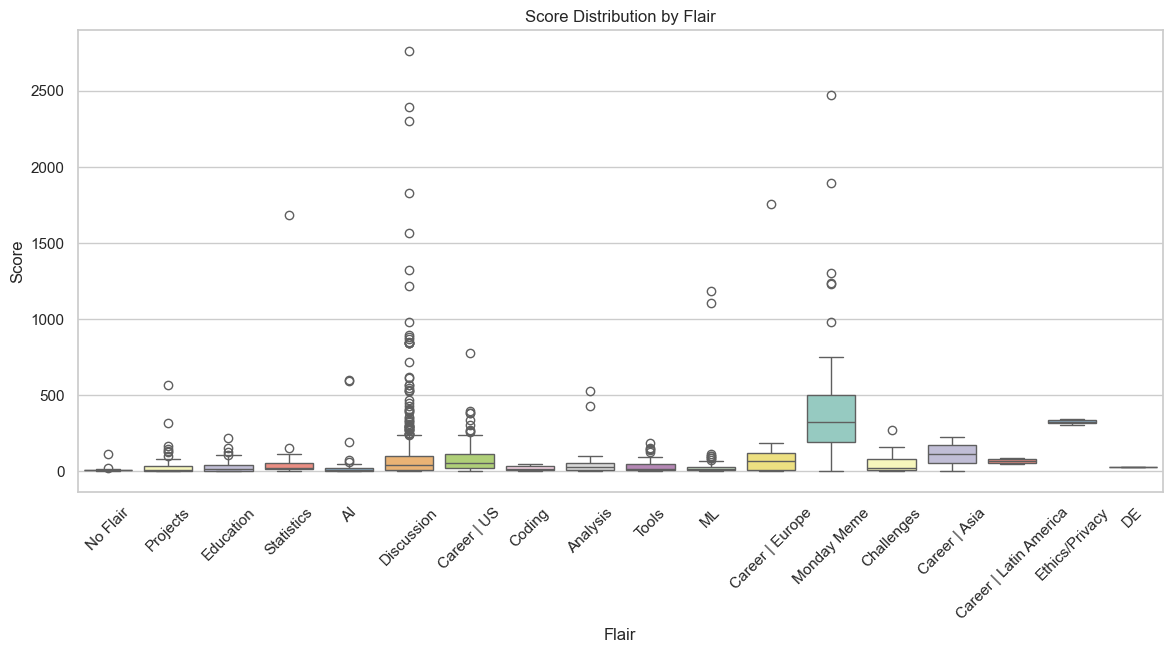

In [47]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x="Flair", y="Score", palette="Set3")
plt.xticks(rotation=45)
plt.title("Score Distribution by Flair")
plt.show()

Content category significantly affects engagement.

**Flair–Engagement Variance:** The boxplot reveals that certain flairs (e.g., "Discussion," "Research") consistently achieve higher median and maximum scores, while others remain confined to lower ranges. Flairs with tighter boxes show consistent engagement; those with long whiskers indicate occasional viral spikes within that category.

**Key Insight:** Content category is a strong engagement driver—choose flairs associated with higher median scores. However, variability within each flair suggests that execution (timing, title clarity, relevance) still matters. Even low-median flairs can produce successful posts with strong fundamentals.

#### <span style="color:salmon">pie chart: Top 5 flairs + Others grouped</span>

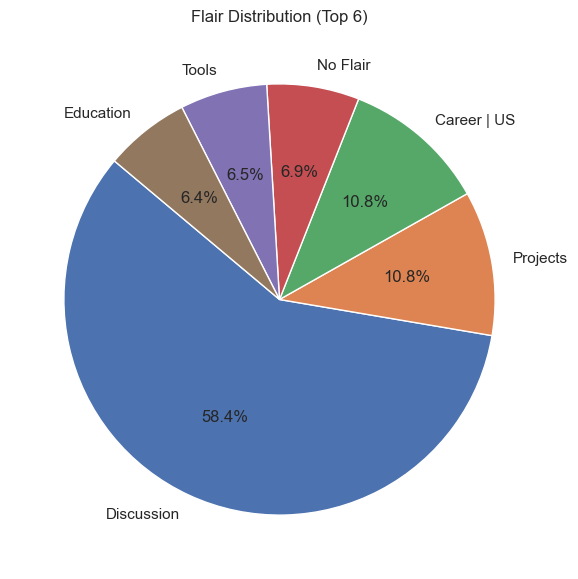

In [ ]:
top_flairs = df['Flair'].value_counts()
TOP_N = 5
top = top_flairs.head(TOP_N)
others = top_flairs.iloc[TOP_N:].sum()
labels = list(top.index) + (['Other'] if others > 0 else [])
sizes = list(top.values) + ([others] if others > 0 else [])

colors = sns.color_palette('pastel', len(labels))

fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, pctdistance=0.75)
ax.set_title('Flair Distribution (Top 5 + Other)')
ax.axis('equal')
plt.tight_layout()
plt.show()

### <span style="color: lime">10. Key Findings</span>

- **Engagement drivers:** Higher scores and comment counts are strongly associated with overall engagement.
- **Timing:** Weekday activity is higher; peak engagement occurs between 12–21 ET.
- **Flair effect:** Certain flairs consistently show higher median scores.
- **Distribution:** Engagement is right-skewed — a small number of posts drive most visibility.
- **Modeling:** Simple models capture moderate signal; richer features are needed for stronger predictions.

### <span style="color:red">11. Limitations of the Study</span>

- Dataset limited to r/datascience — findings may not generalize to other communities.
- Relative timestamps and timezone conversions introduce timing uncertainty.
- Scraping can miss removed/deleted posts and hidden comments, biasing counts.
- Models use a small feature set; text/contextual signals are not fully captured.
- Engagement (score/comments) is affected by Reddit algorithms, not purely organic interest.

### <span style="color:violet">12. Conclusion</span>

This analysis shows that posting time, flair (content category), and early visibility strongly influence engagement on r/datascience. Basic predictive models reveal moderate signal but would benefit from richer text features, interaction histories, and larger datasets to improve accuracy and generalizability.

Next steps: expand feature engineering (text embeddings, author history), collect more data, and evaluate models across multiple subreddits to test generalizability.